# WP13 — Tedizolid / fosfat dış tahmin hazırlığı

Bu defter yeni ilaç tahmini veya eğitim yapmaz. SIVEXTRO PDF/SIDER tedizolid etiketi yok. **Arama parçacıklarında beklenmedik güvenlilik bilgisi maruziyeti oldu; tam araştırmacı bilgi körlüğü iddiası yok.** Kimyasal girdiler yalnız DrugBank yapı kaydı ve frozen RDKit tanımlarıyla hazırlanmıştır. Gerçek dış deney kullanıcı kararını bekler.

,id,alias_ID_overlap,name_overlap,full_key_overlap,connectivity_overlap,DBSALT_child_count,secondary_ID_count,in_registry,outside_frozen62
0,DB09042,[],[],[],[],0,0,True,True
1,DB14569,[],[],[],[],0,0,True,True


,id,name,MW,LogP,HBD,HBA,TPSA,XML_InChIKey,rdkit_inchikey,components,chiral_assigned,chiral_unassigned
0,DB09042,Tedizolid phosphate,450.323,1.5127,2,8,152.79,QCGUSIANLFXSGE-GFCCVEGCSA-N,QCGUSIANLFXSGE-GFCCVEGCSA-N,1,1,0
1,DB14569,Tedizolid,370.344,1.3957,1,7,106.26,XFALPSLJIHVRKE-GFCCVEGCSA-N,XFALPSLJIHVRKE-GFCCVEGCSA-N,1,1,0


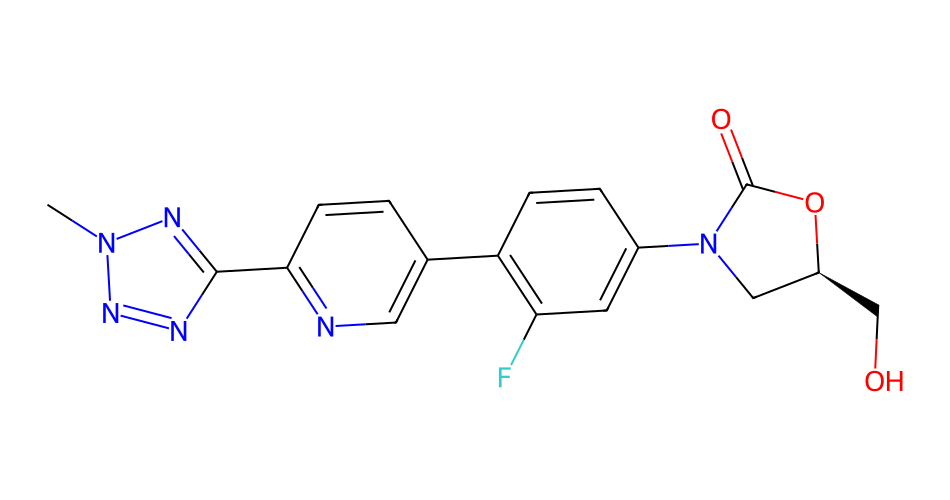

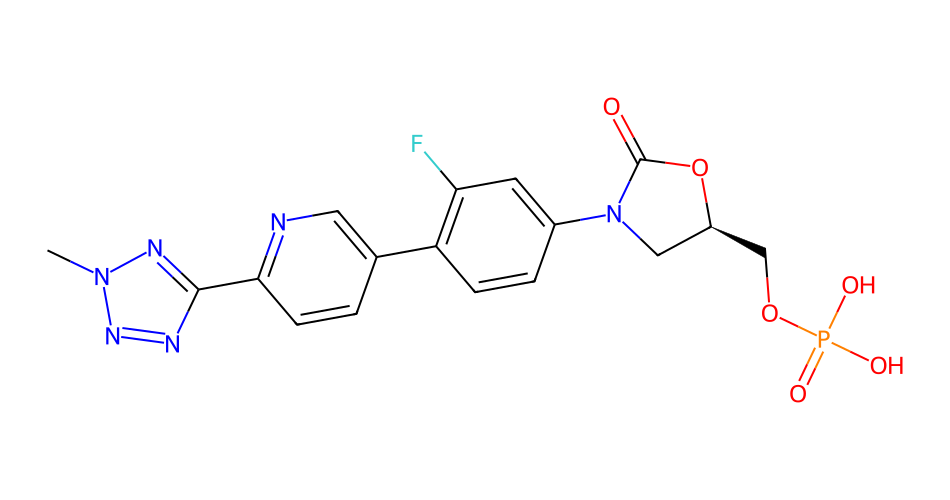

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP13/tedizolid_preparation_v1';F=ROOT/'reports/figures/WP13/tedizolid_preparation_v1'
display(pd.read_json(Q/'identity_vs_frozen62.json'))
chem=pd.read_csv(Q/'chemical_QC_features.csv');display(chem[['id','name','MW','LogP','HBD','HBA','TPSA','XML_InChIKey','rdkit_inchikey','components','chiral_assigned','chiral_unassigned']])
from IPython.display import Image
for name in ['DB14569_structure.png','DB09042_structure.png']:display(Image(filename=str(F/name),width=850))


**Yorum:** Etkin tedizolid ve fosfat ön ilacı iki farklı InChIKey/bağlantısallık yapısıdır. İkisi de frozen62/fit envanterinin dışında; fosfat bir karşı iyon silme işlemiyle temizlenmez. Stereokimya belirtilmiş, yeni stereo üretilmedi. RDKit HBA/LogP tanımları kaynak ChemAxon sayılarıyla karıştırılmaz. Birincil temsil önerisi DB14569; kullanıcı onayı olmadan yeni skor yok.

,query,cohort_drug,similarity,method
0,DB09042,DB00601,0.337209,Morgan radius2 2048bit; diagnostic only
1,DB09042,DB00976,0.181159,Morgan radius2 2048bit; diagnostic only
2,DB09042,DB01044,0.174757,Morgan radius2 2048bit; diagnostic only
3,DB09042,DB00978,0.171717,Morgan radius2 2048bit; diagnostic only
4,DB09042,DB01137,0.171717,Morgan radius2 2048bit; diagnostic only
62,DB14569,DB00601,0.371795,Morgan radius2 2048bit; diagnostic only
63,DB14569,DB00978,0.186813,Morgan radius2 2048bit; diagnostic only
64,DB14569,DB01137,0.186813,Morgan radius2 2048bit; diagnostic only
65,DB14569,DB01165,0.186813,Morgan radius2 2048bit; diagnostic only
66,DB14569,DB00976,0.183206,Morgan radius2 2048bit; diagnostic only


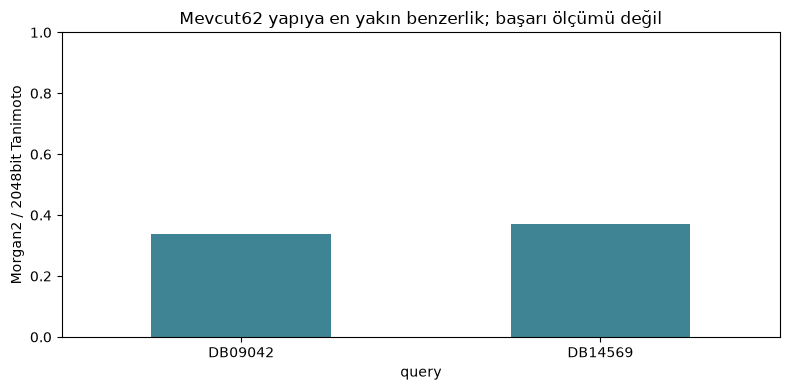

,accession,role_from_XML,taxid,features56_present,finite,string_id,strict_PPI700_degree_existing_induced_graph
0,P21397,enzyme,9606,True,True,9606.ENSP00000340684,4
1,P27338,enzyme,9606,True,True,9606.ENSP00000367309,4


,fold,accession,in_frozen_train_proteins,PPI700_incident_pairs,audit_read_only_no_query_executed
0,1,P21397,True,4,True
1,1,P27338,True,4,True
2,2,P21397,True,4,True
3,2,P27338,True,4,True
4,3,P21397,False,0,True
5,3,P27338,False,0,True
6,4,P21397,True,4,True
7,4,P27338,True,4,True
8,5,P21397,True,4,True
9,5,P27338,True,4,True


In [2]:

sim=pd.read_csv(Q/'structure_similarity_to62.csv');display(sim.groupby('query').head(5))
fig,ax=plt.subplots(figsize=(8,4));nearest=sim.groupby('query').similarity.max();nearest.plot.bar(ax=ax,rot=0,color='#3e8495');ax.set(ylabel='Morgan2 / 2048bit Tanimoto',title='Mevcut62 yapıya en yakın benzerlik; başarı ölçümü değil',ylim=(0,1));plt.tight_layout();plt.savefig(F/'03_identity_similarity_diagnostic.png',dpi=160);plt.show()
display(pd.read_csv(Q/'human_protein_QA.csv'));display(pd.read_csv(Q/'fold_PPI_scope.csv'))


**Yorum:** En yakın yapı Linezolid, tam kimlik/bağlantısallık eşliği yok. İnsan enzyme rolleri MAOA/MAOB; bakteriyel23S RNA ayrı. PPI her fold için aynı değil:3.foldta iki protein train evreninde yok. Bu, hesaplanmış sıfır katkı değil, ilgili train yolunun yokluğudur. A1P1 dış adapter parity'si henüz yapılmadı.

,queries,PT_scores
status,,
ABSTAIN,16,0
PARITY_PASS,108,27854


,max_error
transform_error,0.000000e+00
score_error,1.110223e-16


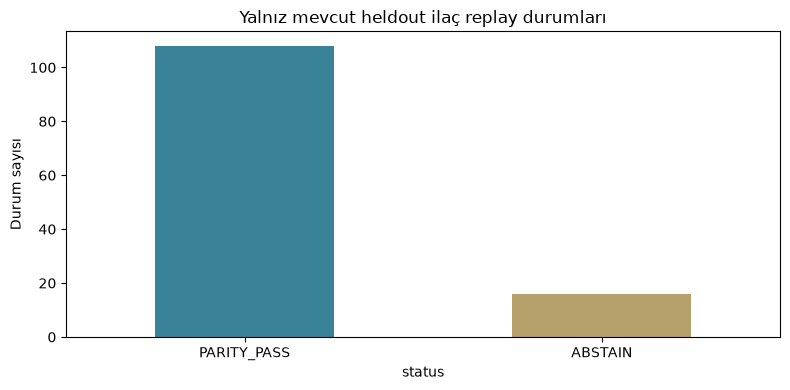

,öneri_ve_kapı
primary_head_sizes,"[220, 262, 267, 270, 275]"
primary_common_head,201
proposal,all5 frozen primary B1 separately; optional equal-weight common-head mean only after user approval
single_model_or_ensemble,PENDING_USER_APPROVAL
representation_proposal,DB14569 active tedizolid; DB09042 distinct phosphate prodrug sensitivity only if separately appr...
external_scoring,NOT_RUN


In [3]:

r=pd.read_csv(Q/'B1_heldout_replay.csv');display(r.groupby('status').agg(queries=('drug_id','size'),PT_scores=('PT','sum')));display(r[['transform_error','score_error']].max().to_frame('max_error'))
fig,ax=plt.subplots(figsize=(8,4));r.status.value_counts().plot.bar(ax=ax,rot=0,color=['#398297','#b6a16c']);ax.set(title='Yalnız mevcut heldout ilaç replay durumları',ylabel='Durum sayısı');plt.tight_layout();plt.savefig(F/'04_existing_heldout_replay.png',dpi=160);plt.show()
display(pd.read_json(Q/'model_policy_options.json',typ='series').to_frame('öneri_ve_kapı'))


**Yorum:**108eski heldout query/27854skor parity PASS,16abstention. Yeni tedizolid skoru yok. Dönüşümfarkı0, skorhatası yaklaşık1,11×10⁻¹⁶. Beşprimary B1 ayrı önerilir;201ortakPT ortalaması ancak önceden onaylı ek politika olabilir. Feature/temsil/model/prospektüs sonucu kilitlenmeden referans karşılaştırması başlamaz.

In [4]:

display(pd.read_json(Q/'blindness_audit.json',typ='series').to_frame('dürüstlük_ve_kapsam'))
display(pd.read_json(Q/'xml_read_audit.json',typ='series').to_frame('ham_kaynak_okuma'))


,dürüstlük_ve_kapsam
SIDER_tedizolid_labels_accessed,False
SIVEXTRO_PDF_opened,False
incidental_search_safety_snippets_exposure,True
strict_analyst_blindness,COMPROMISED_BY_SEARCH_SNIPPETS
adverse_snippets_used_in_inputs_or_selection,False
external_scores,0
chemical_inputs,only DrugBank SMILES + frozen RDKit descriptor definitions
prodrug_relation_reference,https://pubmed.ncbi.nlm.nih.gov/24875463/
PubChem_property_requests,web accessor inaccessible; local request ConnectionError; no PubChem response saved
scope_limit,No claim of fully prospective analyst-blind experiment; independent reviewer recommended


,ham_kaynak_okuma
path,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\DrugBank\drugbank_all_full_database.xml\fu...
source_export,{'{http://www.w3.org/2001/XMLSchema-instance}schemaLocation': 'http://www.drugbank.ca http://www...
size,1898100846
mtime_ns,1776457048961300200
unchanged,True
elapsed_seconds,62.790416
method,iterparse depth2 only; stop after two IDs; no label/safety export
records_found,2


**Yorum:** Körlük maruziyeti saklanmaz; kaynak girdisinin outcome-free olması araştırmacının tamamen kör olduğu anlamına gelmez. Dış inference/SHAP/PDF karşılaştırması NOT_RUN. İnsan/temsil/yöntem kararları kullanıcıyı bekler. Kimyasal yapı ve model replay teknik doğruluğu klinik başarı değildir.